# Third year CH2306

In [1]:
import particlespy as ps # this whole section is loading the information and code needed from different python packages
import numpy as np
import matplotlib.pyplot as plt
import hyperspy.api as hs
import pandas as pd
import cv2

from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor
from segment_anything.utils import transforms
import torch
import sys
import h5py
import json

from skimage import exposure
from skimage.measure import regionprops,regionprops_table
from skimage.segmentation import clear_border
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

E:\Uni\Cardiff\Anaconda\envs\hyperspy_env\lib\site-packages\pandas\core\computation\expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
%matplotlib inline

## Segement anything - NP commands
by https://github.com/ArdaGen/STEM-Automated-Nanoparticle-Analysis-YOLOv8-SAM/tree/main/scripts

In [3]:
# -*- coding: utf-8 -*-
"""
Created on Fri Jul 28 16:11:43 2023

@author: ardag
"""

def particle_analysis(masks, boxes, pixel_size,path_to_csv_file, save=False):
    Diameter = []
    Area = []
    pixel_size = pixel_size  #* pixel_scale 
    for i in range(len(boxes)):
      mask = masks[i,:,:]
      mask = clear_border(mask)
      properties = ['area']
      props = regionprops_table(mask, properties=properties)
      y = props['area']
      A = y*pixel_size*pixel_size
      Area.append(A)
      D = (np.sqrt(A/3.14))*2
      Diameter.append(D)
      
    
    Diameter = [i for i in Diameter if i > 0]
    Diameter = np.array(Diameter)
    Area = [i for i in Area if i > 0]
    Area = np.array(Area)
    print('Mean Diameter : ' + str(np.round(np.mean(Diameter),2)) +' nm')
    print('Mean Area : ' + str(np.round(np.mean(Area),2))+' nm\u00b2') 
    
    fig, axs = plt.subplots(1, 2, sharey = False, tight_layout = False, figsize=(5, 3))
    axs[0].hist(Diameter, bins = 30, facecolor='#2ab0ff', edgecolor='#e0e0e0', linewidth=0.5, alpha=0.7)
    axs[0].set_title("Diameter")
    axs[0].set_xlabel('nm')
    axs[1].hist(Area, bins = 30, facecolor='red', edgecolor='#e0e0e0', linewidth=0.5, alpha=0.7)
    axs[1].set_title("Area")
    axs[1].set_xlabel('nm\u00b2')
    
    if save == True:
        Diameter= np.concatenate(Diameter)
        Area = np.concatenate(Area)
        dict = {'Diameter (nm)' : Diameter,'Area (nm2)' : Area}
        df = pd.DataFrame(dict)
        df.to_csv(path_to_csv_file)
    plt.show()
    return Diameter, Area

def object_detection (img_x, img, path_to_image, img_size=1024, pred_score = 0.25, overlap_thr =0.5, save = False, s_txt = False):
    from ultralytics import YOLO
    path_to_weights_obj = "best12x.pt" # Weights for the YOLO
    model = YOLO(path_to_weights_obj)
    model.to('cuda')
    # Run detection on the image
    results = model.predict(source = img_x, imgsz = img_size, conf = pred_score, max_det= 4000, iou = overlap_thr, save_txt = s_txt)
    
    # Get bounding boxes
    for result in results:
        boxes = result.boxes
     
    bbox = boxes.xyxy.tolist()
    #class_id=results[0].boxes.cls.cpu().numpy().astype(int)
    #points = [item[:2] for item in bbox]
    # Visualize bounding boxes
    res_plotted = results[0].plot(labels=False, line_width=2, img=img)
    plt.figure(figsize=(8, 8))
    plt.axis('off')
    plt.imshow(res_plotted)
    if save == True:
        plt.savefig(path_to_image,bbox_inches='tight', pad_inches = 0)
    plt.show()
    #plot_bboxes(img, results[0].boxes.boxes, score=False)
    
    return bbox


def segmentation(img, bbox, erode = False, dilate = False, kernel_size =(5, 5) ):


    # Load the model
    sam_checkpoint = r"E:\Coding\SegmentAnythingModel\ArdaGen_STEM\sam_vit_b_01ec64.pth" # weights for the SAM path
    model_type = "vit_b"
    device = "cuda"
    sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
    sam.to(device=device)
    predictor = SamPredictor(sam)


    # Run model on the image
    predictor.set_image(img)


    input_boxes = torch.tensor(bbox, device=predictor.device)
    transformed_boxes = predictor.transform.apply_boxes_torch(input_boxes, img.shape[:2])
    masks, _, _ = predictor.predict_torch(
        point_coords=None,
        point_labels=None,
        boxes=transformed_boxes,
        multimask_output=False,
    )
    
    masks_array = masks.cpu().numpy().squeeze()
    masks3D_array = masks_array.astype('uint8')
    
    if erode == True:
        # Erode
        
        kernel = np.ones((kernel_size), np.uint8)
        masks3D_erode = []
        for mask in masks3D_array:
            mask = cv2.erode(mask, kernel)
            masks3D_erode.append(mask)
        masks3D_erode = np.asarray(masks3D_erode)
        masks3D_array = masks3D_erode 
        
    if dilate == True:
        # Erode
        
        kernel = np.ones((kernel_size), np.uint8)
        masks3D_erode = []
        for mask in masks3D_array:
            mask = cv2.dilate(mask, kernel)
            masks3D_erode.append(mask)
        masks3D_erode = np.asarray(masks3D_erode)
        masks3D_array = masks3D_erode 
    
    return masks3D_array


def segmentation_fast(img, bbox):


    from ultralytics import SAM
    model = SAM('mobile_sam.pt')
    device = "cpu"

    results = model.predict(img, bboxes=bbox, save=False, device=device)

    for result in results:
        mask = result.masks
    masks3D_array = mask.data
    masks3D_array = masks3D_array.cpu().numpy()
    masks3D_array= masks3D_array.astype('uint8')
    
    return masks3D_array

def show_mask(mask, ax, random_color=False, save = False):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    mask_image = mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    ax.imshow(mask_image)

def visualize_mask (masks, img, path_to_imageseg, img_size = (256, 256), save = False):
    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.resize(img, img_size))
    for mask in masks:
        show_mask(cv2.resize(mask, img_size), plt.gca(), random_color=True)
    plt.axis('off')
    if save == True:
        plt.savefig(path_to_imageseg, bbox_inches='tight', pad_inches = 0)
    plt.show()

def show_box(box, ax):
    x0, y0 = box[0], box[1]
    w, h = box[2] - box[0], box[3] - box[1]
    ax.add_patch(plt.Rectangle((x0, y0), w, h, edgecolor='green', facecolor=(0,0,0,0), lw=2))

def velox_emd (path, adap = False):
    file = h5py.File(path,'r', rdcc_nbytes=10485760)

    list_data= list(file['Data/Image'].values())
    group = list_data[0]
    data = group['Data']
    tempmetadata = group['Metadata'][:, 0]
    validmetadataindex = np.where(tempmetadata > 0)
    metadata = tempmetadata[validmetadataindex].tobytes()
    metadata_json = json.loads(metadata.decode('utf-8','ignore'))
    pixel_size = round(float(metadata_json["BinaryResult"]["PixelSize"]["width"]) * 1e9, 3) 
    detector = metadata_json["BinaryResult"]["Detector"]
    data_squeezed = np.squeeze(data[:])
    
    if adap == True:
        data_squeezed = exposure.equalize_adapthist(data_squeezed, clip_limit=0.01)
        
  
    if detector == 'HAADF':
        data_squeezed_8bit = ((data_squeezed/np.max(data_squeezed))*255).astype('uint8')
        data_squeezed_inverted =cv2.bitwise_not(data_squeezed_8bit)
        magnification = metadata_json['CustomProperties']['StemMagnification']['value']
        scan_size = metadata_json['Scan']['ScanSize']['width']
        img_x = cv2.cvtColor(data_squeezed_inverted, cv2.COLOR_GRAY2RGB)
        img =  cv2.cvtColor(data_squeezed_8bit, cv2.COLOR_GRAY2RGB) 
        print ( 'Detector : ' + str(detector))
        print( 'Mag : ' + str(magnification))
        print( 'Scan size :' + str(scan_size))
        print( 'Pixel size (nm) : ' + str(pixel_size))
        

    else :
        data_squeezed_8bit = ((data_squeezed/np.max(data_squeezed))*255).astype('uint8')
        img = cv2.cvtColor(data_squeezed_8bit, cv2.COLOR_GRAY2RGB) 
        magnification = round( float(metadata_json['Optics']['NominalMagnification']), 1)
        frame_size = data_squeezed_8bit.shape[0]
        print ( 'Detector : ' + str(detector))
        print( 'Mag : ' + str(magnification))
        print ('Image size :' + str(frame_size))
        print( 'Pixel size (nm) : ' + str(pixel_size))
        img_x = img
    plt.figure(figsize=(8, 8))
    plt.axis('off')
    plt.imshow(img)
    return img_x, img, pixel_size

## Example Processing

In [5]:
path= r"C:\Users\ellak\OneDrive - Cardiff University\phd\images\CH2306_CHT550\TEM\1"

In [ ]:
dataList = hs.load(path +r"\*_aligned.tif") # this loads in any file that ends in aligned.tif. change everything before the \ to where your files are.

In [ ]:
datafile = dataList[0] # pick an image from the list. change the number in brackets

In [ ]:
datafile.plot() # plot your image. you'll see its a stack of all the aligned images

In [ ]:
data = datafile.sum() # this will sum all images in the stack

In [ ]:
data.plot() # now you can see, just the 1 image is in the "data" variable.

In [ ]:
#data can be 8bit, 16 bit or 32 bit - this converts data type to correct version for the correct version.
data_squeezed = np.squeeze(data.data[:])
data_squeezed_8bit = ((data_squeezed/np.max(data_squeezed))*255).astype('uint8')
img = cv2.cvtColor(data_squeezed_8bit, cv2.COLOR_GRAY2RGB)
img_x = img
pixel_size = data.axes_manager.signal_axes[0].scale
print(pixel_size) # in um or nm - check axes! if it's not 0.1 approx, might need to scale!

In [ ]:
path_to_image = r''
boxes = object_detection(img_x, img, path_to_image, img_size = 1024, pred_score = 0.2, overlap_thr = 0.2, save = False) 

You can see it's detected some nanoparticles and some support regions. by manually filtering by the largest nanoparticle, we can ensure only accurate data is included.

In [ ]:
masks = segmentation(img_x, boxes)

In [ ]:
# set up new lists to use
Diameter = []
Area = []
newBoxes = []
for i in range(len(boxes)):
    mask = masks[i,:,:]
    mask = clear_border(mask)
    properties = ['area'] 
    props = regionprops_table(mask, properties=properties) # this uses skimage to calulate the properties requested!
    y = props['area']
    A = y*pixel_size*pixel_size # scale based on pixel size
    D = (np.sqrt(A/3.14))*2
    if D.size == 1: # checks that D is valid! otherwise "particle" may actually be noise.
        number = D.item() 
        if number < 12 and number > 0.1 : # PICK THIS VALUE CAREFULLY TO FILTER OUT FALSE FLAGS. 
          # for each sample, you should know the maximum observed particle diameter. thats D>
          #D>0.1 filters out anything too small, as thats just noise.
          newBoxes.append(boxes[i])
          Area.append(A)
          Diameter.append(D)

newMasks = []
newMasks = segmentation(img_x, newBoxes)
print(len(newMasks))

In [ ]:
path_to_imageseg = r''
visualize_mask(newMasks, img, path_to_imageseg, img_size = (256, 256), save = False)
# check the plot - are you happy with the detected particles? are they outlined well?
# its better to miss 1 than to add false ones - the missed ones can always be added manually.

In [ ]:
path_to_csv_file = r''
diameter, area = particle_analysis(newMasks, newBoxes, pixel_size, path_to_csv_file, save = False)
# finally, this plots the particle size distribution and averages!
# beneath the plots, this shows the standard deviation to 2 decimal places, 
# remember its only for within the image so will be high!
print(f"Standard deviation of diameter = {np.std(diameter):.2f}")
print(f"Standard deviation of area = {np.std(area):.2f}")

## Bulk code - don't worry about running this!

This section of code shows how I processed each sample's data - you don't need to worry about this.


0: 736x1024 558 Particles, 50.4ms
Speed: 4.7ms preprocess, 50.4ms inference, 4.0ms postprocess per image at shape (1, 3, 736, 1024)


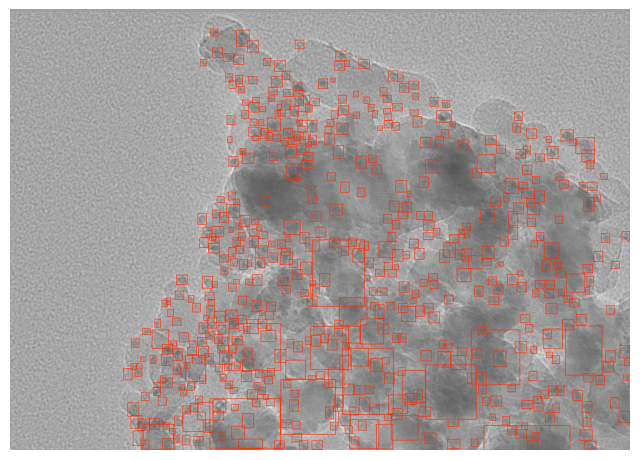

In [ ]:
# Batch Processing TEM
import gc
import glob
path_to_csv_file = r''
path_to_image = r''
path_to_dm3_files = path +r'\*aligned.tif'

diameter_final = []
area_final = []
newBoxes = []
for v in glob.glob(path_to_dm3_files):
    newBoxes = []
    datafile = hs.load(v) #load each data file
    data = datafile.sum()# sum the stack
    data_squeezed = np.squeeze(data.data[:]) #take the "data" out of the whole file - it includes metadata and other information about it, but we just want the image.
    data_squeezed_8bit = ((data_squeezed/np.max(data_squeezed))*255).astype('uint8') #makes sure image is the correct data type
    img = cv2.cvtColor(data_squeezed_8bit, cv2.COLOR_GRAY2RGB) #makes sure the image is in correct format
    img_x = img #sets comparative image
    if data.axes_manager[0].units == 'µm':
        pixel_size = data.axes_manager.signal_axes[0].scale * 1000
    else:
        pixel_size = data.axes_manager.signal_axes[0].scale #takes the pixel size from metadata, in nm.
    with torch.no_grad(): # to make sure the memory is not unneccessarily stored!
        boxes = object_detection(img_x, img, path_to_image, img_size = 1024, pred_score = 0.2, overlap_thr = 0.2, save = False) # draws a box around the possible nanoparticles
        masks = segmentation_fast(img_x, boxes) # segments the exact nanoparticle within this box 
        # remove falsely detected support sections by thresholding a maximum
        for i in range(len(boxes)):
            mask = masks[i,:,:]
            mask = clear_border(mask)
            properties = ['area']
            props = regionprops_table(mask, properties=properties)
            y = props['area']
            A = y*pixel_size*pixel_size
            D = (np.sqrt(A/3.14))*2
            if D.size == 1: # checks that D is valid! otherwise "particle" may actually be noise.
                number = D.item() 
            if D < 15 and D > 0.1 : # PICK THIS VALUE CAREFULLY TO FILTER OUT FALSE FLAGS 
              newBoxes.append(boxes[i])
    del boxes # removes old lists from memory 
    del masks
    if len(newBoxes) > 0 :
        with torch.no_grad():
            newMasks = segmentation_fast(img_x, newBoxes)
            diameter, area = particle_analysis(newMasks, newBoxes, pixel_size, path_to_csv_file, save = False) # analyses them        
            diameter_final.append(diameter) # saves the results for this dataset
            area_final.append(area) # same as above, but for area instead of diameter
            del newMasks
    del newBoxes
    del data
    del data_squeezed
    with torch.no_grad():
        torch.cuda.empty_cache()
        gc.collect()
diameter_total = np.concatenate((diameter_final))
area_total = np.concatenate((area_final))

In [ ]:
# convert array into dataframe to save 
DF = pd.DataFrame(diameter_total) 
# save the dataframe as a csv file 
DF.to_csv(r"diameter_totalSample1.csv")


In [ ]:
#if out of memory
torch.cuda.empty_cache()

In [ ]:
len(diameter_total) # this is how many particles were counted! 

In [ ]:
mean = np.mean(diameter_total)
std = np.std(diameter_total)

In [ ]:
np.round(mean, decimals = 3) # this is the average size, rounded.

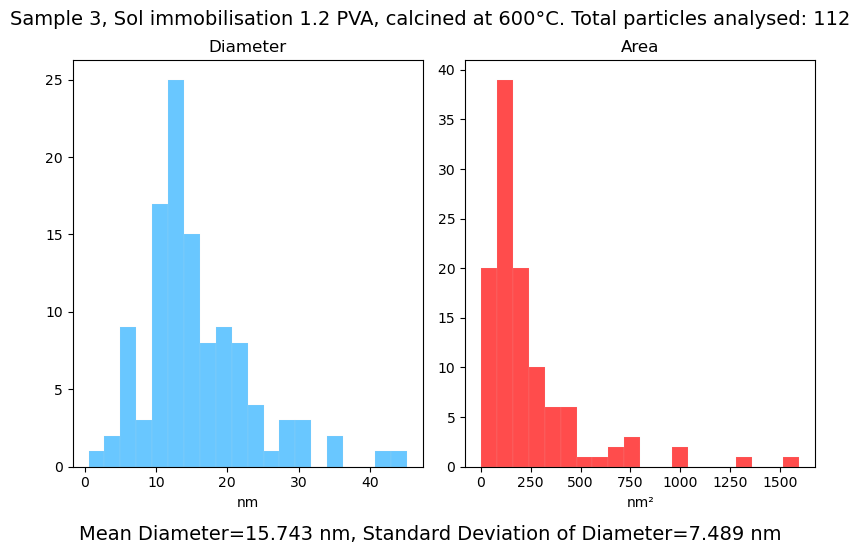

In [170]:
fig, axs = plt.subplots(1, 2, sharey = False, tight_layout = False, figsize=(8, 5))
axs[0].hist(diameter_total, bins =140, facecolor='#2ab0ff', edgecolor='#e0e0e0', linewidth=0.1, alpha=0.7)
axs[0].set_title("Diameter")
axs[0].set_xlabel('nm')
axs[1].hist(area_total, bins = 140, facecolor='red', edgecolor='#e0e0e0', linewidth=0.1, alpha=0.7)
axs[1].set_title("Area")
axs[1].set_xlabel('nm\u00b2')
fig.text(0.5, 1.0,f"Sample 2, Sol immobilisation 1.2 PVA. Total particles analysed: {len(diameter_total)}", fontsize=14, ha='center')
fig.text(0.5, -0.03, f"Mean Diameter={np.round(mean, decimals = 3)} nm, Standard Deviation of Diameter={np.round(std, decimals = 3)} nm", fontsize=14, ha='center')
plt.savefig(r'DiameterAreaPlot_Sample1.png', dpi = 300, bbox_inches='tight', pad_inches=0.2)
plt.show()